In [1]:
%run general.ipynb
%matplotlib inline

RESULTS_DIR = '../results'
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Output directory: {RESULTS_DIR}')


/home/xuhuan/miniconda3/envs/qiime2-2022.2-my/lib/python3.8/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_repeats=1, random_state=None as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "
/home/xuhuan/miniconda3/envs/qiime2-2022.2-my/lib/python3.8/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_splits=3, n_repeats=1 as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "


2026-05-18 16:16:13 WARNING These have metadata but do not have data - dropped (415): {'H46.surface.10x.9.12.17.metal.3', 'BLANK8.7G', 'BLANK8.5B', 'H45.surface.10x.9.12.17.metal.4', 'surface.ctrl.TE.09.14.15.1p.metal.2', 'BLANK11.11C', 'H5.skin.TE.09.14.15.11a.metal.4', 'BLANK.3.B3', 'H1.skin.TE.09.14.15.3p.glass.1', 'BLANK.3.G3', 'BLANK8.3A', 'H3.skin.TE.09.14.15.1p.metal.2', 'surface.ctrl.9.11.17.plastic.1sec.5', 'BLANK8.5F', 'H1.skin.TE.09.14.15.11a.glass.1', 'H5.skin.TE.09.14.15.3p.metal.2', 'BLANK13.6.6H', 'H1.skin.TE.9.14.15.Rpalm', 'H10.skin.20x.9.14.17.plastic', 'surface.ctrl.TE.09.14.15.11a.plastic.1', 'BLANK8.4F', 'BLANK12.D12', 'BLANK1.1A', 'BLANK12.A10', 'H46.surface.10x.9.12.17.metal.2', 'H2.skin.TE.09.14.15.1p.metal.1', 'H4.skin.TE.09.14.15.1p.glass.1', 'H4.skin.TE.09.14.15.3p.glass.4', 'BLANK12.B9', 'H4.skin.TE.09.14.15.3p.metal.5', 'H5.skin.TE.09.14.15.1p.glass.4', 'H1.skin.TE.09.14.15.11a.metal.5', 'H2.skin.TE.09.14.15.3p.plastic.2', 'surface.ctrl.TE.09.14.15.4p.plast

### Part 5: **Cross-Time Prediction** Analysis

This part tests the model's long-term stability by training on 2016 data and predicting samples from other years (2015 and 2017).

In [2]:
exp_time_filtered = exp
mat_color_dict = {**MAT_COLOR_DICT, 'skin': '#ff7f0e'}  
exp_time_filtered

AmpliconExperiment ("reference-hit.2026.biom") with 1727 samples, 10511 features

In [3]:
md = pd.read_table('../data/merged_mapping.txt', index_col=0,
                   dtype={'month':str, 'day':str, 'year':str, 'sample_date':str},
                   parse_dates=['sample_date'])
md.pivot_table(values='sample_date', index='experiment', columns=['experiment_category'], aggfunc=len)

experiment_category,material_type,mixed_signal,number_touches,persistence
experiment,,,,
exp201509,384.0,NaN,NaN,NaN
exp201512,288.0,NaN,NaN,NaN
exp201603,369.0,NaN,NaN,111.0
exp201605,NaN,NaN,191.0,NaN
exp201610,NaN,192.0,NaN,NaN
exp201709,354.0,NaN,NaN,249.0


In [4]:
exp_skin_filtered = exp_time_filtered.filter_ids(
    exp_time_filtered.sample_metadata.query('sample_type=="skin" & surface_type in ["Rpalm", "Lpalm"]').index,
    axis=0).filter_sample_categories(
    'individual', min_samples=3)

In [5]:
train2016 = (exp_skin_filtered.filter_samples('year', 2016)
                      .filter_sample_categories('individual', min_samples=3)
                      .filter_by_metadata('_calour_original_abundance', select=lambda i: i > 500)
                      .filter_abundance(0, strict=True))
X = train2016.data
y = train2016.sample_metadata.individual
print(train2016)
hosts = train2016.sample_metadata['individual'].unique().tolist()
train2016.sample_metadata.individual.value_counts()

AmpliconExperiment ("reference-hit.2026.biom") with 283 samples, 6733 features


individual
H1     15
H39    14
H8     14
H40    14
H5     11
H12    10
H28    10
H17    10
H15    10
H13    10
H38    10
H23     9
H16     9
H10     9
H2      9
H9      9
H4      9
H27     8
H19     6
H32     5
H31     5
H33     5
H35     5
H36     5
H34     5
H11     5
H7      5
H18     5
H37     5
H29     4
H22     4
H25     4
H21     4
H26     4
H30     4
H24     4
H6      4
H14     3
H20     2
Name: count, dtype: int64

In [6]:
sample_summary1 = train2016.sample_metadata.experiment.value_counts()
sample_summary1.name = 'train-skin'
sample_summary1

experiment
exp201610    97
exp201605    96
exp201603    90
Name: train-skin, dtype: int64

In [7]:
model2016 = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=11)
model2016.fit(X, y)
print(f"OOB Score for model trained on 2016 data: {model2016.oob_score_}")

OOB Score for model trained on 2016 data: 0.8869257950530035


In [8]:
gs2016 = make_rf_grid_search()
saved_model_path_2016 = os.path.join(RESULTS_DIR, 'prediction-across-months.2016.pkl.bz2')
gs2016 = load_or_fit_model(gs2016, saved_model_path_2016, X, y)


Running model training... (this may take a while)


/home/xuhuan/miniconda3/envs/qiime2-2022.2-my/lib/python3.8/site-packages/sklearn/model_selection/_split.py:666: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(("The least populated class in y has only %d"


In [9]:
test_other_years = (exp_time_filtered.filter_samples('year', 2016, negate=True)
                     .filter_samples('individual', train2016.sample_metadata.individual.unique().tolist())
                     .filter_ids(train2016.feature_metadata.index, axis=1)
                     .filter_by_metadata('_calour_original_abundance', select=lambda i: i > 200)
                    )
test_other_years

AmpliconExperiment ("reference-hit.2026.biom") with 425 samples, 6733 features

In [13]:
jk_cache_path = os.path.join(RESULTS_DIR, 'part5-unified-jackknife.pkl.bz2')

jk_results = compute_cross_year_jackknife(
    model=model2016,
    test_exp=test_other_years,
    cache_path=jk_cache_path,
    progress_every=50,
)

yprob_jk_mean = jk_results['yprob_jk_mean']
jk_bar_year = jk_results['jk_bar_year']
jk_bar_type = jk_results['jk_bar_type']
years_list = jk_results['years_list']
types_list = jk_results['types_list']
year_to_i = jk_results['year_to_i']
type_to_i = jk_results['type_to_i']
max_N = jk_results['max_N']

yprob_rank_jk = yprob_jk_mean.rank(axis=1, ascending=False)


Running unified jackknife on test set...
   Progress: 50/425
   Progress: 100/425
   Progress: 150/425
   Progress: 200/425
   Progress: 250/425
   Progress: 300/425
   Progress: 350/425
   Progress: 400/425
   Progress: 50/425
   Progress: 100/425
   Progress: 150/425
   Progress: 200/425
   Progress: 250/425
   Progress: 300/425
   Progress: 350/425
   Progress: 400/425
Unified Jackknife results saved.


/home/xuhuan/miniconda3/envs/qiime2-2022.2-my/lib/python3.8/site-packages/sklearn/model_selection/_split.py:666: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(("The least populated class in y has only %d"


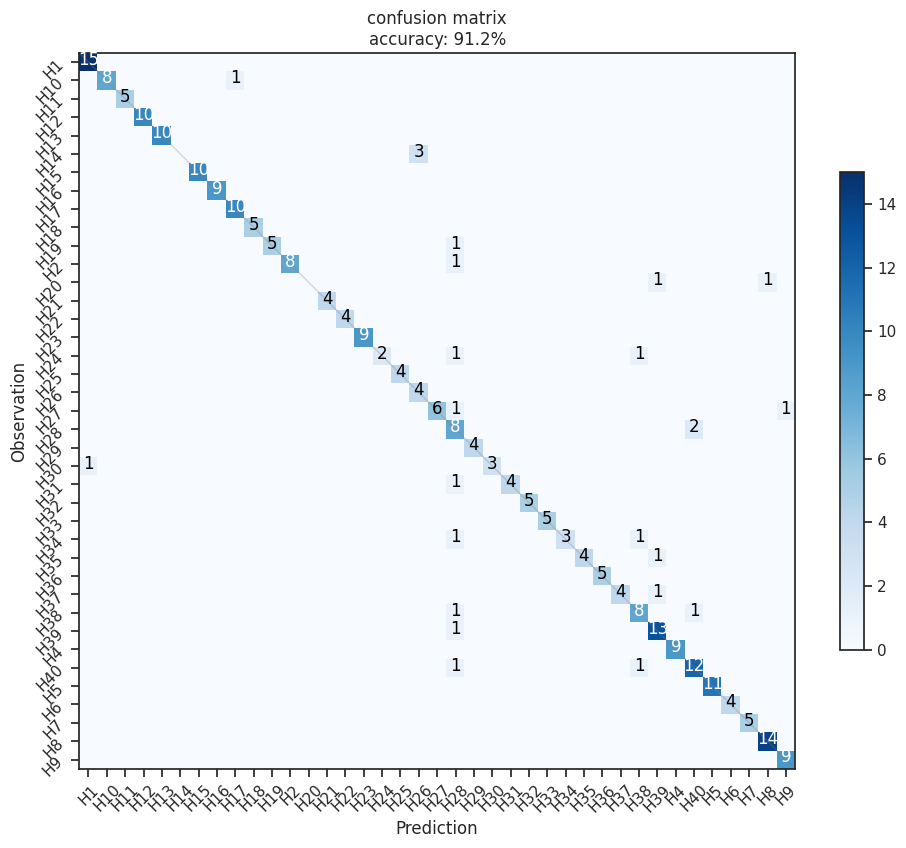

In [14]:
cv_iterator = train2016.classify('individual', RandomForestClassifier(n_estimators=500, random_state=11), cv=StratifiedKFold(3))
cv_results = next(cv_iterator)


fig_cm, ax_cm = plt.subplots(figsize=(10, 10))
plot_cm(cv_results, ax=ax_cm)

if len(fig_cm.axes) > 1:
    cbar_ax = fig_cm.axes[-1]  
    pos = cbar_ax.get_position()
    
    shrink_factor = 0.5 
    new_height = pos.height * shrink_factor

    new_y0 = pos.y0 + (pos.height - new_height) / 2

    cbar_ax.set_position([pos.x0, new_y0, pos.width, new_height])

for text in ax_cm.texts:
    t = text.get_text()
    try:
        if float(t) == 0:
            text.set_text('')
            continue 
    except ValueError:
        pass
    
    x, y = text.get_position()
    text.set_position((x, y + 0.15)) 

plt.show()

d = RESULTS_DIR
save_fig(fig_cm, os.path.join(d, '2016.cm.pdf'))


yprob_rank_cv = cv_results[cv_results.columns[:-2]].select_dtypes(include='number').rank(ascending=False, axis=1)
yprob_rank_cv.index = cv_results['SAMPLE']
ranks_cv_model = defaultdict(list)
ranks_by_year = {}

for sid in cv_results['SAMPLE']:
    obs, y = train2016.sample_metadata.loc[sid, ['individual', 'year']]
    ranks_cv_model[f'{int(y)}'].append(yprob_rank_cv.loc[sid, obs])

ranks_by_year['2016 CV'] = ranks_cv_model['2016']

In [15]:
from scipy import stats

init_plot_style()


markers = ['o', 'o', 'o']
palette = ['#2ca02c', 'gray', '#1f77b4']  # 2015, 2016 CV, 2017

max_N = jk_bar_year.shape[0]
ns = list(range(1, max_N + 1))
max_N_plot = max_N


cv_data = ranks_by_year.get('2016 CV', [])
cv_accs = [sum(1 for r in cv_data if r <= n) / len(cv_data) for n in ns] if cv_data else None
cv_top3 = cv_accs[2] if cv_accs else 0

# Build plot data
plot_data_year = []
year_fold_matrices = {}  # Store for significance testing

# 2015
if 2015 in years_list:
    y_i = years_list.index(2015)
    mask = ((test_other_years.sample_metadata['sample_type'] == 'skin') &
            (test_other_years.sample_metadata['year'] == 2015)).values
    fold_valid = jk_bar_year[:, mask, y_i]
    year_fold_matrices['2015'] = fold_valid
    stats = compute_jackknife_topn_stats(fold_valid)
    means = stats['means']
    se = stats['se']
    auc_max = stats['auc']
    se_auc = stats['se_auc']
    plot_data_year.append({'label': '2015', 'means': means, 'top3_mean': means[2],
                           'se': se, 'auc': auc_max, 'se_auc': se_auc})

# 2016 CV
if cv_accs:
    plot_data_year.append({'label': '2016 CV', 'means': cv_accs, 'top3_mean': cv_top3, 'se': None})

# 2017
if 2017 in years_list:
    y_i = years_list.index(2017)
    mask = ((test_other_years.sample_metadata['sample_type'] == 'skin') &
            (test_other_years.sample_metadata['year'] == 2017)).values
    fold_valid = jk_bar_year[:, mask, y_i]
    year_fold_matrices['2017'] = fold_valid
    stats = compute_jackknife_topn_stats(fold_valid)
    means = stats['means']
    se = stats['se']
    auc_max = stats['auc']
    se_auc = stats['se_auc']
    plot_data_year.append({'label': '2017', 'means': means, 'top3_mean': means[2],
                           'se': se, 'auc': auc_max, 'se_auc': se_auc})

baseline_year = '2015'


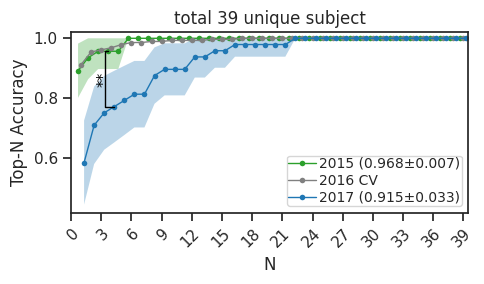

In [16]:
fig_year_err, ax_year_err, curves, bracket_info = plot_precomputed_topn_jackknife(
    curve_data=plot_data_year,
    baseline_label=baseline_year,
    fold_matrices=year_fold_matrices,
    color_dict=palette,
    marker=markers,
    figsize=(5, 3),
    ns=ns,
    pvalue_fn=lambda **ctx: jackknife_auc_unpaired_test(
        ctx['baseline_fold_matrix'],
        ctx['fold_matrix'],
    ),
    label_fn=lambda label, i, data: label,
    jitter_width=0.3,
    alpha_fill=0.3,
    linewidth=1,
    markersize=4,
    legend_loc='lower right',
    legend_kwargs=dict(fontsize=10, handletextpad=0.2, labelspacing=0.2, borderpad=0.1, ncol=2),
    x_anchor_index=3,
    bracket_step=0.40,
    bracket_hook_depth=0.35,
    bracket_fontsize=11,
    bracket_lw=1.0,
)

ax_year_err.set_title('total 39 unique subject', fontsize=12)
ax_year_err.set_xlim(0.5, max_N_plot + 0.5)
ax_year_err.set_ylim(top=1.02)
ax_year_err.set_xticks(range(0, max_N_plot + 1, 3))
ax_year_err.set_xlabel('N')
ax_year_err.set_ylabel('Top-N Accuracy')
ax_year_err.legend(loc='lower right', fontsize=10, handletextpad=0.2, labelspacing=0.2, borderpad=0.1)
rotate_xticklabels(ax_year_err)
plt.tight_layout()
plt.show()


In [17]:
# Cross-Material Top-N Curve
current_palette = sns.color_palette()

current_order = ['skin', 'plastic', 'ceramic', 'metal', 'glass', 'wood']
current_order = [mat for mat in current_order if mat in type_to_i]

markers = ['o', 'o', 'o', 'o', 'o', 'o']
palette = [mat_color_dict[mat] for mat in current_order]

plot_data_type = []
type_fold_matrices = {}

for mat in current_order:
    t_i = type_to_i[mat]
    if mat == 'skin':
        mask = (test_other_years.sample_metadata['surface_type'].isin(['Lpalm', 'Rpalm', 'skin'])).values
    else:
        mask = (test_other_years.sample_metadata['surface_type'] == mat).values
    fold_valid = jk_bar_type[:, mask, t_i]
    type_fold_matrices[mat] = fold_valid
    n_sub = fold_valid.shape[1]
    stats = compute_jackknife_topn_stats(fold_valid)
    means = stats['means']
    se = stats['se']
    auc_max = stats['auc']
    se_auc = stats['se_auc']

    plot_data_type.append({
        'label': mat,
        'means': means,
        'se': se,
        'top3_mean': means[2],
        'auc': auc_max,
        'se_auc': se_auc,
    })


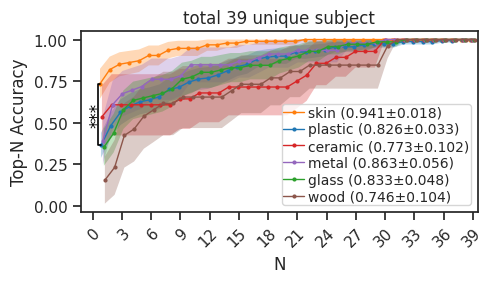

In [18]:
baseline_mat = 'plastic'

fig_type_err, ax_type_err, curves, bracket_info = plot_group_topn_jackknife(
    jk_topn=jk_bar_type,
    sample_metadata=test_other_years.sample_metadata,
    group_order=current_order,
    axis_order=type_to_i,
    metadata_col='surface_type',
    baseline_group=baseline_mat,
    color_dict=palette,
    marker=markers,
    figsize=(5, 3),
    mask_fn=lambda mat: (
        test_other_years.sample_metadata['surface_type'].isin(['Lpalm', 'Rpalm', 'skin']).to_numpy()
        if mat == 'skin'
        else (test_other_years.sample_metadata['surface_type'] == mat).to_numpy()
    ),
    pvalue_fn=lambda **ctx: jackknife_auc_unpaired_test(
        ctx['baseline_fold_matrix'],
        ctx['fold_matrix'],
    ),
    label_fn=lambda label, _, stats: label,
    ns=ns,
    jitter_width=0.1,
    alpha_fill=0.3,
    linewidth=1,
    markersize=3,
    x_anchor=None,
    x_anchor_index=0,
    bracket_step=1,
    bracket_hook_depth=0.35,
    bracket_fontsize=12,
    bracket_lw=1.2,
    auto_left_limit_from_brackets=True,
)

left_limit = 0
if bracket_info:
    left_limit = ax_type_err.get_xlim()[0]

ax_type_err.set_title('total 39 unique subject', fontsize=12)
ax_type_err.set_xlim(left_limit - 0.5, max_N_plot + 0.5)
ax_type_err.set_xticks(range(0, max_N_plot + 1, 3))
ax_type_err.set_xlabel('N')
ax_type_err.set_ylabel('Top-N Accuracy')
rotate_xticklabels(ax_type_err)
ax_type_err.legend(
    loc='lower right',
    fontsize=10,
    labelspacing=0.2,
    handletextpad=0.3,
    handlelength=1.5,
    borderpad=0.1
)
plt.tight_layout()
plt.show()


In [19]:
# --- 6.6c Save Cross-Year/Cross-Material Top-N Figures ---
d = RESULTS_DIR
save_fig(fig_year_err, os.path.join(d, '2016.predict.skin-jk.error.pdf'))
save_fig(fig_type_err, os.path.join(d, '2016.predict.sample-type-jk.error.pdf'))


In [ ]:
# --- 6.4 Feature Analysis ---
# Analyze the abundance and prevalence of important features in the 2016 model to identify stable biomarkers. and prevalence of important features in the 2016 model to identify stable biomarkers.
train2016.feature_metadata['importance'] = model2016.feature_importances_
train2016.feature_metadata['importance_rank'] = train2016.feature_metadata.importance.rank(ascending=False, method='first')
train2016.feature_metadata['sum'] = train2016.data.sum(axis=0).A1
train2016.feature_metadata['sum_rank'] = train2016.feature_metadata['sum'].rank(ascending=False)

In [ ]:
def label_important(rank, n=60):
    return 'important' if rank < n else 'not-important'

train2016.feature_metadata['important'] = [label_important(i) for i in train2016.feature_metadata['importance_rank']]

In [ ]:
train2016_imp = train2016.filter_by_metadata('important', ['NA'], axis='f', negate=True)

In [ ]:
def plot_abund_prevalence(exp: ca.Experiment, field, log=True, ax=None):
    if ax is None:
        from matplotlib import pyplot as plt
        fig, ax = plt.subplots(figsize=(6,12))
    for f, grp in exp.feature_metadata[field].items():
        x, y = compute_prevalence(exp[:, f])
        ax.plot(x, y, color='red' if grp=='important' else 'gray', 
                alpha=1 if grp=='important' else 0.5, 
                linewidth=2 if grp=='important' else 1)

    ax.set_ylabel('Prevalence')
    if log:
        ax.set_xscale("log")
        ax.set_xlabel('Log(Abundance)')
    else:
        ax.set_xlabel('Abundance')
    ax.invert_xaxis()
    return ax

<Axes: xlabel='Log(Abundance)', ylabel='Prevalence'>

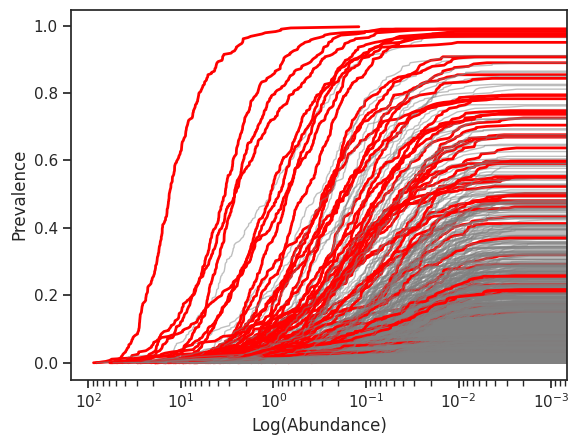

In [ ]:
fig_abund_prev, ax_abund_prev = plt.subplots()
plot_abund_prevalence(train2016_imp.filter_abundance(0.1), 'important', log=True, ax=ax_abund_prev)

In [ ]:
d = RESULTS_DIR
save_fig(fig_abund_prev, os.path.join(d, 'abundance-prevalence.pdf'))


In [ ]:
rank_df = defaultdict(list)
for sample_count in range(1, 15):
    print(f'--- Testing with {sample_count} samples per individual ---')
    samplewise = train2016.downsample('individual', num_keep=sample_count, random_state=9)
    all_individuals = samplewise.sample_metadata['individual'].unique().tolist()
    
    for individual_count in range(2, len(all_individuals)):
        print(f'===== Testing with {individual_count} individuals =====')
        repeat = 0
        seed = 0
        while repeat < 10:
            rand = np.random.RandomState(seed)
            individuals = rand.choice(all_individuals, individual_count, replace=False).tolist()
            
            _train = (train2016.downsample('individual', num_keep=sample_count, random_state=repeat)
                               .filter_samples('individual', individuals)
                               .filter_abundance(0, strict=True))
            _test = (exp_time_filtered.filter_ids(_train.feature_metadata.index, axis=1)
                           .filter_ids(_train.sample_metadata.index, axis=0, negate=True)
                           .filter_samples('individual', individuals))
            
            if _test.shape[0] < 5:
                seed += 1
                continue
            
            rf = RandomForestClassifier(n_estimators=500, random_state=seed)
            rf.fit(_train.data, _train.sample_metadata['individual'])
            yhat = rf.predict_proba(_test.data)
            _df = pd.DataFrame(yhat, columns=rf.classes_, index=_test.sample_metadata.index).rank(axis=1, ascending=False)
            _df['obs'] = _test.sample_metadata['individual'].values
            
            rank_df[(individual_count, sample_count)].append(_df)
            repeat += 1
            seed += 1

--- Testing with 1 samples per individual ---
===== Testing with 2 individuals =====
===== Testing with 3 individuals =====
===== Testing with 4 individuals =====
===== Testing with 5 individuals =====


===== Testing with 6 individuals =====
===== Testing with 7 individuals =====
===== Testing with 8 individuals =====
===== Testing with 9 individuals =====
===== Testing with 10 individuals =====
===== Testing with 11 individuals =====
===== Testing with 12 individuals =====
===== Testing with 13 individuals =====
===== Testing with 14 individuals =====
===== Testing with 15 individuals =====
===== Testing with 16 individuals =====
===== Testing with 17 individuals =====
===== Testing with 18 individuals =====
===== Testing with 19 individuals =====
===== Testing with 20 individuals =====
===== Testing with 21 individuals =====
===== Testing with 22 individuals =====
===== Testing with 23 individuals =====
===== Testing with 24 individuals =====
===== Testing with 25 individuals =====
===== Testing with 26 individuals =====
===== Testing with 27 individuals =====
===== Testing with 28 individuals =====
===== Testing with 29 individuals =====
===== Testing with 30 individuals =====
====

In [ ]:
import pickle
fn = 'sample-individual-counts.pkl.bz2'
print("Saving simulation results...")
with open(fn, 'wb') as f:
    pickle.dump(rank_df, f)

Saving simulation results...


In [ ]:
import pickle
d = RESULTS_DIR
fn = os.path.join(d, 'sample-individual-counts.pkl.bz2')
if not os.path.exists(fn):
    print("Saving simulation results...")
    with open(fn, 'wb') as f:
        pickle.dump(rank_df, f)
else:
    print("Loading pre-computed simulation results...")
    with open(fn, 'rb') as f:
        rank_df = pickle.load(f)


Saving simulation results...


In [ ]:
N = 1
ranks_skin_data = []
for k, v in rank_df.items():
    for i in v:
        rank_list = []
        for sid in i.index:
            if sid in md.index:
                sample_type = md.loc[sid, 'sample_type']
                if sample_type == 'skin':
                    rank = i.loc[sid, i.loc[sid, 'obs']]
                    rank_list.append(rank)
        if len(rank_list) > 0:
            rank_accuracy = np.sum(np.array(rank_list) <= N) / len(rank_list)
            ranks_skin_data.append((k[0], k[1], rank_accuracy))
            
ranks_skin_df = pd.DataFrame(ranks_skin_data, columns=['individuals', 'samples_per_individual', 'accuracy'])

In [ ]:
ave = ranks_skin_df.groupby(['individuals', 'samples_per_individual']).mean()
ave2 = ave.reset_index()

ave3 = ave2.pivot(index='individuals', columns='samples_per_individual', values='accuracy')

/tmp/ipykernel_250510/2422706281.py:43: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for handle in leg.legendHandles:


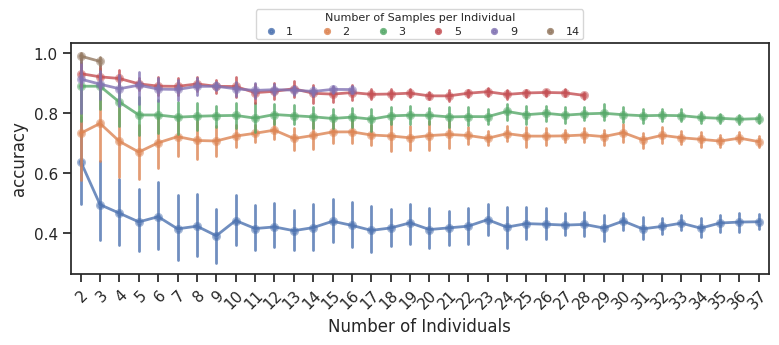

In [ ]:
fig_sim_individuals, ax_sim_individuals = plt.subplots(figsize=(9, 3))

i = [1, 2, 3, 5, 9, 14]

sns.pointplot(x='individuals', y='accuracy', hue='samples_per_individual',
              data=ranks_skin_df.query('samples_per_individual in @i'),
              ax=ax_sim_individuals)

ax_sim_individuals.set_xlabel('Number of Individuals')


ax_sim_individuals.spines['top'].set_visible(True)
ax_sim_individuals.spines['right'].set_visible(True)

for l in ax_sim_individuals.lines:
    l.set_linewidth(2)        
    l.set_linestyle('-')      
    l.set_alpha(0.8)        

for c in ax_sim_individuals.collections:
    c.set_alpha(0.5)          
    if hasattr(c, 'set_sizes'):
        c.set_sizes([20])     

handles, labels = ax_sim_individuals.get_legend_handles_labels()

if handles:
    leg = ax_sim_individuals.legend(
        handles=handles, 
        labels=labels,
        bbox_to_anchor=(.5, 1.08),  
        loc='center', 
        ncol=len(i),                 
        borderaxespad=0., 
        title='Number of Samples per Individual',
        fontsize=8,                 
        title_fontsize=8,            
        labelspacing=0.3,    
        handletextpad=0.4,   
        borderpad=0.3        
    )

    for handle in leg.legendHandles:
        handle.set_alpha(0.8)

        if hasattr(handle, 'set_sizes'):
            handle.set_sizes([10])  

        elif hasattr(handle, 'set_markersize'):
            handle.set_markersize(3)
            handle.set_linewidth(0.5)
rotate_xticklabels(ax_sim_individuals)
plt.show()

In [ ]:
d = RESULTS_DIR
save_fig(fig_sim_individuals, os.path.join(d, 'individual-count.N1.pdf'))


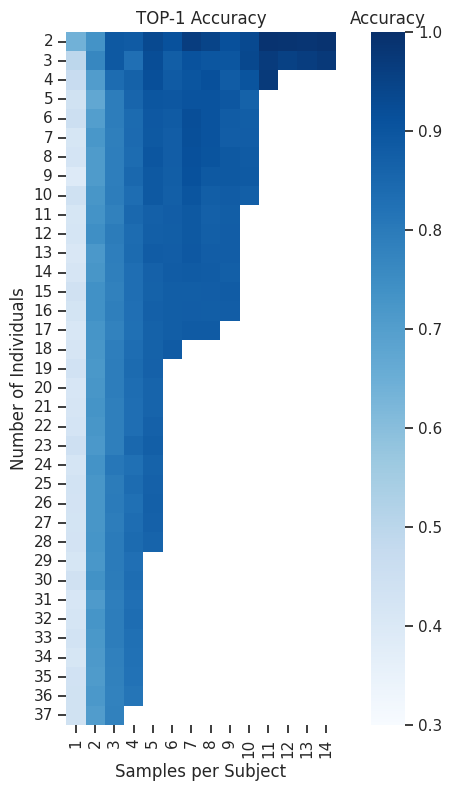

In [ ]:
d = RESULTS_DIR
fig_sim_heatmap1, ax_sim_heatmap1 = plt.subplots(figsize=(9, 9))

plot_simulation_heatmap(ave3, title='TOP-1 Accuracy', ax=ax_sim_heatmap1)

save_fig(fig_sim_heatmap1, os.path.join(d, 'individual-sample-count-heatmap.N1.pdf'))

plt.show()

In [ ]:
N = 2
ranks_skin_data_n2 = []
for k, v in rank_df.items():
    for i in v:
        rank_list = []
        for sid in i.index:
            if sid in md.index and md.loc[sid, 'sample_type'] == 'skin':
                rank = i.loc[sid, i.loc[sid, 'obs']]
                rank_list.append(rank)
        if len(rank_list) > 0:
            rank_accuracy = np.sum(np.array(rank_list) <= N) / len(rank_list)
            ranks_skin_data_n2.append((k[0], k[1], rank_accuracy))
ranks_skin_df_n2 = pd.DataFrame(ranks_skin_data_n2, columns=['individuals', 'samples_per_individual', 'accuracy'])

In [ ]:
ave_n2 = ranks_skin_df_n2.groupby(['individuals', 'samples_per_individual']).mean()
ave2_n2 = ave_n2.reset_index()
ave3_n2 = ave2_n2.pivot(index='individuals', columns='samples_per_individual', values='accuracy')

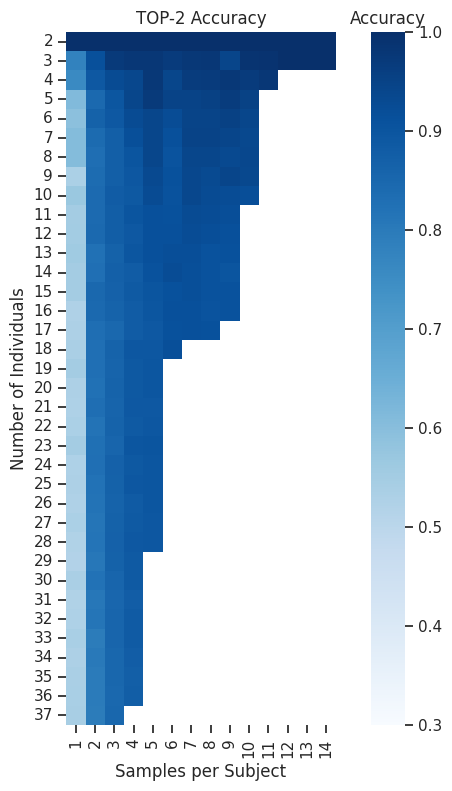

In [ ]:
d = RESULTS_DIR
fig_sim_heatmap2, ax_sim_heatmap2 = plt.subplots(figsize=(9,9))
plot_simulation_heatmap(ave3_n2, title='TOP-2 Accuracy', ax=ax_sim_heatmap2) # Use set_title to place at top
save_fig(fig_sim_heatmap2, os.path.join(d, 'individual-sample-count-heatmap2.N2.pdf'))


In [ ]:
N = 3
ranks_skin_data_n3 = []
for k, v in rank_df.items():
    for i in v:
        rank_list = []
        for sid in i.index:
            if sid in md.index and md.loc[sid, 'sample_type'] == 'skin':
                rank = i.loc[sid, i.loc[sid, 'obs']]
                rank_list.append(rank)
        if len(rank_list) > 0:
            rank_accuracy = np.sum(np.array(rank_list) <= N) / len(rank_list)
            ranks_skin_data_n3.append((k[0], k[1], rank_accuracy))
ranks_skin_df_n3 = pd.DataFrame(ranks_skin_data_n3, columns=['individuals', 'samples_per_individual', 'accuracy'])

In [ ]:
ave_n3 = ranks_skin_df_n3.groupby(['individuals', 'samples_per_individual']).mean()
ave2_n3 = ave_n3.reset_index()
ave3_n3 = ave2_n3.pivot(index='individuals', columns='samples_per_individual', values='accuracy')

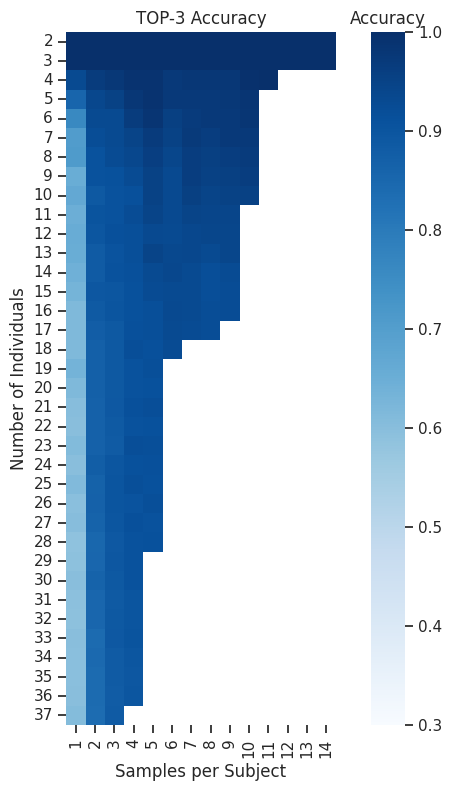

In [ ]:
d = RESULTS_DIR
fig_sim_heatmap3, ax_sim_heatmap3 = plt.subplots(figsize=(9,9))
plot_simulation_heatmap(ave3_n3, title='TOP-3 Accuracy', ax=ax_sim_heatmap3)
save_fig(fig_sim_heatmap3, os.path.join(d, 'individual-sample-count-heatmap3.N3.pdf'))

In [ ]:
wuf = read('../data/extracted_qza/weighted_unifrac_distance_matrix/8d668add-c00f-4e13-8800-cad9e89d022c/data/distance-matrix.tsv', format='lsmat', into=DistanceMatrix)
skin_samples = md.query('sample_type=="skin"')

In [ ]:
dist_tdelta = []
for ind in skin_samples.individual.unique():
    ss = skin_samples.query('individual==@ind')
    for s1, s2 in combinations(ss.itertuples(), 2):
        if s1.Index in wuf.ids and s2.Index in wuf.ids:
            d = wuf[s1.Index, s2.Index]
            td = s1.sample_date - s2.sample_date
            td = abs(td.days)
            dist_tdelta.append([ind, d, td, s1.Index, s2.Index])
dist_tdelta_df = pd.DataFrame(dist_tdelta, columns=['individual', 'distance', 'delta_time', 'sample1', 'sample2'])

In [ ]:
individuals_with_enough_data = dist_tdelta_df.individual.value_counts()
individuals_to_plot = individuals_with_enough_data.index[individuals_with_enough_data > 150]

In [ ]:
dist_t_filtered = dist_tdelta_df.query('individual in @individuals_to_plot')

In [ ]:
dist_t_grouped = dist_t_filtered.groupby(['individual', 'delta_time'])['distance'].mean()
dist_t_reset = dist_t_grouped.reset_index()

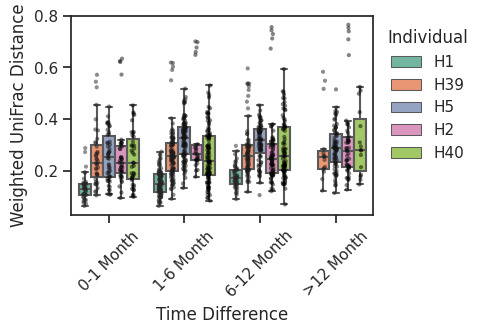

In [ ]:
df_plot = dist_t_filtered.copy()

target_order = ['H1', 'H39', 'H5', 'H2', 'H40']
df_plot['individual'] = pd.Categorical(df_plot['individual'], categories=target_order, ordered=True)

bins = [-np.inf, 30, 180, 365, np.inf]
labels = ['0-1 Month', '1-6 Month', '6-12 Month', '>12 Month']
df_plot['Time Difference'] = pd.cut(df_plot['delta_time'], bins=bins, labels=labels)

fig, ax = plt.subplots(figsize=(5, 3.5))

sns.boxplot(x='Time Difference', y='distance', hue='individual', 
            hue_order=target_order, palette='Set2',
            data=df_plot, ax=ax, fliersize=0)

sns.stripplot(
    data=df_plot, 
    x='Time Difference', 
    y='distance', 
    hue='individual', 
    hue_order=target_order,
    dodge=True,         
    marker='o',         
    color='black',      
    alpha=0.5,          
    size=3,             
    jitter=True,        
    ax=ax
)

ax.set_xlabel('Time Difference')
ax.set_ylabel('Weighted UniFrac Distance')
ax.tick_params(axis='x', rotation=45) 

handles, labels_leg = ax.get_legend_handles_labels()
n_individuals = len(target_order) 
ax.legend(
    handles[:n_individuals], 
    labels_leg[:n_individuals], 
    title='Individual', 
    bbox_to_anchor=(1, 1), 
    loc='upper left', 
    frameon=False
)

plt.tight_layout()
save_fig(fig, os.path.join(RESULTS_DIR, 'temporal_stability.pdf'))
plt.show()